# 02 Velocity decomposition: fault-parallel and vertical velocity maps

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13 (MintPy importable, pygmt).
```

**What this notebook does.** It takes the GNSS-tied ascending and descending
velocity mosaics (`mosaic/<orbit>_velocity_NA.h5`, made by the preparation
chain described in notebook 01) and solves, pixel by pixel, for the
fault-parallel (FP) and vertical (Up) velocity. The solve is MintPy's own
`asc_desc2horz_vert`, with our two inputs and the mean strike of the mapped
Hayward trace as the horizontal direction. We assume all horizontal motion is
fault-parallel, the standard two-look assumption (Methods M2).

**Outputs** (all in `outputs/02_velocity_decomposition/`):
- `fp_velocity_map.h5` with datasets `fp_velocity` and `up_velocity` (mm/yr)
- `fp_velocity.h5`, `up_velocity.h5` as MintPy velocity files and their `.grd`
  versions from `save_gmt.py`, for GMT / QGIS
- `fp_velocity_xfault_swath200m_dist1000m.csv`: the cross-fault transects at
  the five creepmeters
- `02_velocity_stats.txt` and the registry rows `02_*`

**Figures**: the rotated FP / Up velocity maps (Fig 1a) and the five transects.

**What to check when you run it.** The CHECK cells re-derive the decomposition
at random pixels with our own design matrix (insar_utils, tested) and compare
with MintPy's numbers; the vertical velocity should be near zero away from
landslides and the bay margin; the fault-crossing step at CFW1 should match the
creepmeter (7.0 mm/yr) to within a millimetre a year.

In [1]:
import os
import sys

import insar_utils as utils                      # our shared helpers (tested)
from TulePond_filepaths import (common_paths, paths_mosaic, creepmeters,
                                unit, az_smooth_n, paths_out, repo_dir)

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # MintPy HDF5 products
import pyproj                                    # UTM <-> lon/lat
import xarray as xr                              # gridded arrays for pygmt
import matplotlib.pyplot as plt                  # quick-look plots
import pygmt                                     # publication maps
import mintpy
from mintpy.asc_desc2horz_vert import asc_desc2horz_vert   # THE decomposition, MintPy's own

## Constants

One fault azimuth for the whole map: a raster row has no tectonic meaning, so
the strike that enters the decomposition is the mean of the smoothed local
strike of the mapped trace. Where local strike matters (the cross-fault creep
time series) it is applied crossing by crossing in notebook 03.

MintPy's `horz_az_angle` is measured ANTI-clockwise from north; our strike is a
compass bearing (clockwise), so it enters as `-strike`. This is the convention
pinned by `tests/test_insar_utils.py`.

In [2]:
notebook = "02_velocity_decomposition"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

geom_step = 20        # MintPy medians the geometry in windows of this many pixels (its default)
swath_m = 200.0       # transects: along-fault half-width of the swath (m)
max_dist_m = 1000.0   # transects: cross-fault half-extent (m)
n_check = 200         # pixels re-derived by hand in the CHECK cell
rng = np.random.default_rng(0)

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(paths_mosaic["ascending"]["vel_NA_file"], paths_mosaic["ascending"]["geo_file"],
           paths_mosaic["descending"]["vel_NA_file"], paths_mosaic["descending"]["geo_file"],
           common_paths["fault_profiles"])

Registry for 02_velocity_decomposition: run 580724c8, git 0b537fc+


## LOAD and SHOW: the two velocity mosaics and their geometry

Both orbits are on the SAME 30 m UTM grid (EPSG 32610), so no resampling is
needed and a pixel in the ascending map is the same ground pixel in the
descending map. The cell asserts that before anything else. Velocities are
stored in m/yr and converted to mm/yr at the boundary (`unit = 1000`).

In [3]:
insar = {}
for orbit in ("ascending", "descending"):
    # exactly as Hayward_DISP-S1/analysis/run06_decompose_velocity.py: velocity
    # m/yr -> mm/yr, geometry as stored (float32); MintPy handles the no-data
    with h5py.File(paths_mosaic[orbit]["vel_NA_file"], "r") as h:
        vel = h["velocity"][:] * unit
        attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in h.attrs.items()}
    with h5py.File(paths_mosaic[orbit]["geo_file"], "r") as h:
        inc = h["incidenceAngle"][:].astype(np.float32)
        azi = h["azimuthAngle"][:].astype(np.float32)
    insar[orbit] = {"vel": vel, "inc": inc, "azi": azi, "attrs": attrs}
    print(f"{orbit}: grid {attrs['LENGTH']} x {attrs['WIDTH']} px, {attrs['X_STEP']} m, EPSG {attrs['EPSG']}, "
          f"ref pixel ({attrs['REF_LON']}, {attrs['REF_LAT']}) UTM")
    print(f"   velocity valid {100 * np.isfinite(vel).mean():.1f}%, median {np.nanmedian(vel):+.2f} mm/yr, "
          f"incidence {np.nanmin(inc[inc > 0]):.1f} to {np.nanmax(inc):.1f} deg, azimuth median {np.nanmedian(azi[inc > 0]):.1f} deg")
    print("")

attrs = insar["ascending"]["attrs"]
for key in ("X_FIRST", "Y_FIRST", "X_STEP", "Y_STEP", "WIDTH", "LENGTH", "EPSG", "REF_LAT", "REF_LON"):
    assert attrs[key] == insar["descending"]["attrs"][key], f"asc/desc grids differ in {key}"
assert attrs["EPSG"] == "32610" and float(attrs["X_STEP"]) == 30.0, "expected a 30 m UTM zone 10 grid"
assert insar["ascending"]["vel"].shape == insar["ascending"]["inc"].shape, "geometry grid differs from velocity grid"

# ascending looks WEST (satellite west of the target), descending looks EAST:
# the East component of the ground->satellite vector has opposite signs
ia, aa = insar["ascending"]["inc"], insar["ascending"]["azi"]
id_, ad = insar["descending"]["inc"], insar["descending"]["azi"]
L_asc = utils.los_unit_vector(np.nanmedian(ia[ia > 0]), np.nanmedian(aa[ia > 0]))
L_des = utils.los_unit_vector(np.nanmedian(id_[id_ > 0]), np.nanmedian(ad[id_ > 0]))
assert L_asc[0] < 0 < L_des[0], "look directions are not asc-west / desc-east: check the azimuth convention"
print("median LOS unit vectors (E, N, U): asc", L_asc.round(3), " desc", L_des.round(3))

ascending: grid 3048 x 2333 px, 30.0 m, EPSG 32610, ref pixel (586935.0, 4155585.0) UTM


   velocity valid 40.6%, median -1.62 mm/yr, incidence 37.9 to 42.7 deg, azimuth median 99.9 deg

descending: grid 3048 x 2333 px, 30.0 m, EPSG 32610, ref pixel (586935.0, 4155585.0) UTM
   velocity valid 37.5%, median +0.42 mm/yr, incidence 41.8 to 46.0 deg, azimuth median 260.5 deg

median LOS unit vectors (E, N, U): asc [-0.638 -0.112  0.762]  desc [ 0.685 -0.114  0.719]


In [4]:
# quick look: both LOS velocity mosaics on their native grid
fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharex=True, sharey=True)
for ax, orbit in zip(axes, ("ascending", "descending")):
    im = ax.imshow(insar[orbit]["vel"], cmap="RdBu_r", vmin=-10, vmax=10, interpolation="none")
    ax.set_title(f"{orbit} LOS velocity (mm/yr, + toward satellite)", fontsize=9)
    ax.set_xlabel("column"); ax.set_ylabel("row")
fig.colorbar(im, ax=axes, shrink=0.6, label="mm/yr")
plt.show()

/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_4562/1400863651.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## The fault strike that enters the decomposition

`hayward_fault_profiles.csv` holds the mapped trace resampled every 100 m with
the local cross-fault azimuth `profile_az`. A 21-point rolling median (2.1 km)
removes digitising glitches while keeping the real curvature. The strike is
`profile_az + 90` (a compass bearing, pointing south-east along the fault).

In [5]:
prof = pd.read_csv(common_paths["fault_profiles"])
prof["az_smooth"] = prof["profile_az"].rolling(az_smooth_n, center=True, min_periods=3).median()
strike = float(np.nanmean(prof["az_smooth"] + 90.0))

print(f"trace: {len(prof)} crossings, latitude {prof.ft_lat.min():.3f} to {prof.ft_lat.max():.3f}")
print(f"local strike ranges {np.nanmin(prof.az_smooth) + 90:.1f} to {np.nanmax(prof.az_smooth) + 90:.1f} deg")
print(f"mean strike used for the map: {strike:.2f} deg (compass bearing, clockwise from north)")
assert 130 < strike < 160, "the Hayward strikes ~N36W; a mean strike outside 130-160 means the trace file is wrong"

trace: 791 crossings, latitude 37.414 to 37.991
local strike ranges 135.8 to 158.2 deg
mean strike used for the map: 144.10 deg (compass bearing, clockwise from north)


## RUN: MintPy's two-look decomposition

`asc_desc2horz_vert` solves, in windows of `geom_step` x `geom_step` pixels
with the window-median geometry,

$$ \begin{bmatrix} d_{asc} \\ d_{desc} \end{bmatrix} =
   \begin{bmatrix} \sin\theta_a \cos(\alpha_a - \alpha_h) & \cos\theta_a \\
                   \sin\theta_d \cos(\alpha_d - \alpha_h) & \cos\theta_d \end{bmatrix}
   \begin{bmatrix} v_{FP} \\ v_{U} \end{bmatrix} $$

with $\alpha_h$ = `-strike`. Pixels missing on either track are set to NaN on
both so the solve never mixes a valid value with a zero.

In [6]:
v_asc, v_des = insar["ascending"]["vel"], insar["descending"]["vel"]
both = np.isfinite(v_asc) & np.isfinite(v_des)
print(f"pixels valid on both tracks: {both.sum()} ({100 * both.mean():.1f}% of the grid)")

dlos = np.stack([v_asc, v_des]).astype(np.float32)
dlos[:, ~both] = np.nan
los_inc = np.stack([insar["ascending"]["inc"], insar["descending"]["inc"]]).astype(np.float32)
los_azi = np.stack([insar["ascending"]["azi"], insar["descending"]["azi"]]).astype(np.float32)

fp, up = asc_desc2horz_vert(dlos, los_inc, los_azi, horz_az_angle=-strike, step=geom_step)
fp, up = fp.astype(np.float64), up.astype(np.float64)

print("")
print(f"FP velocity: {100 * np.isfinite(fp).mean():.1f}% valid, median {np.nanmedian(fp):+.2f} mm/yr, "
      f"5-95% {np.nanpercentile(fp, 5):+.2f} to {np.nanpercentile(fp, 95):+.2f}")
print(f"Up velocity: median {np.nanmedian(up):+.2f} mm/yr, 5-95% {np.nanpercentile(up, 5):+.2f} to {np.nanpercentile(up, 95):+.2f}")

pixels valid on both tracks: 2398301 (33.7% of the grid)
decomposing asc/desc into horz/vert direction in windows of 20x20 ...
[>                                                 ]

[>                                                 ]

[>                        2%                       ] 3/153    0s /     2s

[=>                       3%                       ] 4/153    0s /     2s

[=>                       3%                       ] 5/153    0s /     2s

/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/mintpy/asc_desc2horz_vert.py:142: RuntimeWarning: All-NaN slice encountered
  med_los_inc_angle = np.nanmedian(los_inc_angle[:, y0:y1, x0:x1], axis=(1,2))
/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/mintpy/asc_desc2horz_vert.py:143: RuntimeWarning: All-NaN slice encountered
  med_los_az_angle  = np.nanmedian( los_az_angle[:, y0:y1, x0:x1], axis=(1,2))


... (146 outputs left out)

[==================================================] 152/153

[==================================================] 153/153

FP velocity: 33.3% valid, median +1.31 mm/yr, 5-95% -4.37 to +13.21

Up velocity: median -0.78 mm/yr, 5-95% -3.46 to +1.81


## CHECK 1: re-derive the decomposition by hand at random pixels

MintPy is a black box to the reader, so we redo the solve ourselves at
`n_check` random pixels with `utils.design_matrix_up_fp` (our own, tested
design matrix) and `numpy.linalg.solve`. To be a fair comparison we use the
same window-median geometry MintPy uses. Agreement to 1e-3 mm/yr (float32
storage) means our convention and MintPy's are the same thing.

In [7]:
# MintPy returns NaN where a window has no valid geometry; report, then
# compare only where it returned a number
lost = both & ~np.isfinite(fp)
print(f"pixels valid on both tracks but NaN after the solve: {lost.sum()} ({100 * lost.sum() / both.sum():.2f}%)")

rows, cols = np.where(both & np.isfinite(fp))
pick = rng.choice(len(rows), size=n_check, replace=False)
diff_fp, diff_up = [], []
for r, c in zip(rows[pick], cols[pick]):
    r0, c0 = (r // geom_step) * geom_step, (c // geom_step) * geom_step      # MintPy's window for this pixel
    inc_w = np.nanmedian(los_inc[:, r0:r0 + geom_step, c0:c0 + geom_step], axis=(1, 2))
    azi_w = np.nanmedian(los_azi[:, r0:r0 + geom_step, c0:c0 + geom_step], axis=(1, 2))
    G = utils.design_matrix_up_fp(inc_w, azi_w, strike)               # columns [U, FP]
    U_hand, FP_hand = np.linalg.solve(G, [v_asc[r, c], v_des[r, c]])
    diff_fp.append(FP_hand - fp[r, c])
    diff_up.append(U_hand - up[r, c])
diff_fp, diff_up = np.array(diff_fp), np.array(diff_up)

print(f"hand solve minus MintPy at {n_check} pixels: FP max |diff| {np.abs(diff_fp).max():.2e} mm/yr, "
      f"Up max |diff| {np.abs(diff_up).max():.2e} mm/yr")
assert np.abs(diff_fp).max() < 1e-3 and np.abs(diff_up).max() < 1e-3, "our design matrix and MintPy disagree"
print("PASS: MintPy's decomposition equals ours (same convention, same numbers)")

pixels valid on both tracks but NaN after the solve: 28769 (1.20%)


hand solve minus MintPy at 200 pixels: FP max |diff| 6.42e-06 mm/yr, Up max |diff| 2.49e-06 mm/yr
PASS: MintPy's decomposition equals ours (same convention, same numbers)


## CHECK 2: the sign and size of the fault-parallel step

Right-lateral creep means the EAST block moves south-east relative to the
west block. FP is positive along the strike bearing (south-east), so the east
side of the trace must be MORE positive than the west side. We test that on
the whole fault with the cross-fault transects at the five creepmeters,
fitted with `v = a + b d + step H(d > 0)` (the step is the creep rate seen by
the velocity field), and compare with the creepmeter rates from the
validation notebook (CFW1 7.0 mm/yr).

In [8]:
def sample_xfault(grid, attrs, prof, swath_m, max_dist_m):
    """Cross-fault transect at each creepmeter: centre = trace point nearest
    the creepmeter latitude; every finite pixel within +/- swath_m along strike
    and +/- max_dist_m across, as (code, signed distance [+ = east], value)."""
    utm = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True)
    ft_x, ft_y = utm.transform(prof["ft_lon"].values, prof["ft_lat"].values)
    x_first, x_step = float(attrs["X_FIRST"]), float(attrs["X_STEP"])
    y_first, y_step = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
    nrow, ncol = grid.shape
    px = abs(x_step)
    rows = []
    for code, la, lo, name in creepmeters:
        i = int(np.argmin(np.abs(prof["ft_lat"].values - la)))
        x0, y0 = ft_x[i], ft_y[i]
        cross_az = np.deg2rad(prof["az_smooth"].values[i])          # profile_az = cross-fault, toward the east side
        strike_az = np.deg2rad(prof["az_smooth"].values[i] + 90.0)  # along the fault
        cE, cN = np.sin(cross_az), np.cos(cross_az)
        sE, sN = np.sin(strike_az), np.cos(strike_az)
        n = 0
        for d in np.arange(-max_dist_m, max_dist_m + px, px):        # cross-fault
            for s in np.arange(-swath_m, swath_m + px, px):          # along-fault
                E = x0 + d * cE + s * sE
                N = y0 + d * cN + s * sN
                col = int(round((E - x_first) / x_step))
                row = int(round((N - y_first) / y_step))
                if 0 <= row < nrow and 0 <= col < ncol and np.isfinite(grid[row, col]):
                    rows.append((code, float(d), float(grid[row, col])))
                    n += 1
        print(f"  transect {code} ({name}, lat {la}): {n} finite pixels")
    return pd.DataFrame(rows, columns=["code", "dist_m", "fp_vel"])


def step_fit(d, v):
    """v = a + b*d + step*[d > 0]; the step is the fault-crossing creep rate.
    Solved by least squares (three unknowns, so linregress alone cannot do it)."""
    G = np.column_stack([np.ones_like(d), d, (d > 0).astype(float)])
    a, b, step = np.linalg.lstsq(G, v, rcond=None)[0]
    return step, a + b * d + step * (d > 0)


xf = sample_xfault(fp, attrs, prof, swath_m, max_dist_m)
xf_csv = os.path.join(out_dir, f"fp_velocity_xfault_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.csv")
xf.to_csv(xf_csv, index=False)
print(f"Saved transects to: {xf_csv}")

steps = {}
print("")
print("fault-parallel velocity step across the trace (east minus west, mm/yr):")
for code, la, lo, name in creepmeters:
    sub = xf[xf.code == code]
    step, pred = step_fit(sub.dist_m.values, sub.fp_vel.values)
    # the simplest possible route to the same number: median of the near-field east side minus west side
    east = sub[(sub.dist_m > 0) & (sub.dist_m <= 300)].fp_vel.median()
    west = sub[(sub.dist_m < 0) & (sub.dist_m >= -300)].fp_vel.median()
    steps[code] = step
    print(f"  {code}: step fit {step:5.2f}   |   median(east 0-300 m) - median(west) = {east - west:5.2f}")
    assert step > 0, f"{code}: negative step means the east block moves NW: the sign convention is wrong"
print("PASS: every creepmeter site shows a right-lateral (positive) step")

  transect CPP1 (Pinole Point, lat 37.9895): 425 finite pixels
  transect CTM1 (Temescal, lat 37.8439): 668 finite pixels
  transect COZ1 (Oakland Zoo, lat 37.7535): 738 finite pixels
  transect CHP1 (Palisade Street, lat 37.66274): 839 finite pixels
  transect CFW1 (Fremont, lat 37.53237): 951 finite pixels


Saved transects to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/fp_velocity_xfault_swath200m_dist1000m.csv

fault-parallel velocity step across the trace (east minus west, mm/yr):
  CPP1: step fit  3.65   |   median(east 0-300 m) - median(west) =  4.49
  CTM1: step fit  3.77   |   median(east 0-300 m) - median(west) =  4.26
  COZ1: step fit  3.11   |   median(east 0-300 m) - median(west) =  3.34
  CHP1: step fit  4.94   |   median(east 0-300 m) - median(west) =  4.86


  CFW1: step fit  6.62   |   median(east 0-300 m) - median(west) =  6.90
PASS: every creepmeter site shows a right-lateral (positive) step


## Save the maps: MintPy files, GMT grids, and the combined product

`fp_velocity.h5` and `up_velocity.h5` are written as MintPy velocity files
(attributes grafted from the mosaic), so MintPy's own tools work on them, and
converted to `.grd` with `save_gmt.py` for GMT and QGIS. The combined
`fp_velocity_map.h5` carries both datasets and the strike used.

In [9]:
src = paths_mosaic["ascending"]["vel_NA_file"]
prov = {"PROVENANCE": utils.provenance_stamp(notebook, repo_dir), "FAULT_AZIMUTH_DEG": strike, "UNIT": "mm/year"}
for name, arr in (("fp_velocity", fp), ("up_velocity", up)):
    h5 = os.path.join(out_dir, f"{name}.h5")
    utils.write_new_h5(arr, h5, src, dataset="velocity", extra_attrs=prov)
    utils.run_command(["save_gmt.py", h5, "-o", os.path.join(out_dir, f"{name}.grd")])

map_h5 = os.path.join(out_dir, "fp_velocity_map.h5")
with h5py.File(map_h5, "w") as h:
    h.create_dataset("fp_velocity", data=fp.astype(np.float32), compression="gzip")
    h.create_dataset("up_velocity", data=up.astype(np.float32), compression="gzip")
    for k in ("X_FIRST", "Y_FIRST", "X_STEP", "Y_STEP", "WIDTH", "LENGTH", "EPSG", "REF_LAT", "REF_LON"):
        h.attrs[k] = attrs[k]
    for k, v in prov.items():
        h.attrs[k] = str(v)
print(f"Saved FP + Up maps to: {map_h5}")

Saved velocity to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/fp_velocity.h5
Running: /Users/dlindsay/miniforge3/envs/opera_disp_feb13/bin/save_gmt.py /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/fp_velocity.h5 -o /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/fp_velocity.grd


writing >>> /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/fp_velocity.grd
Done.
Saved velocity to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/up_velocity.h5
Running: /Users/dlindsay/miniforge3/envs/opera_disp_feb13/bin/save_gmt.py /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/up_velocity.h5 -o /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/up_velocity.grd


writing >>> /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/up_velocity.grd
Done.


Saved FP + Up maps to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/fp_velocity_map.h5


## Figure: the rotated velocity maps

The maps are drawn in the strike-rotated frame used throughout the paper:
`u` runs along the mean strike from Point Pinole (0 km) increasing SOUTH, `v`
is the cross-fault distance with the EAST side positive. Nothing is bent: the
raster is looked up (nearest neighbour, no interpolation, so masked
landslides stay masked) at the rotated grid points, and the curved trace is
drawn on top. The panel is Cartesian km at true aspect, so the scale bar is
exact.

In [10]:
def strike_frame(prof, strike, epsg):
    """(to_uv, trace_u, trace_v): u along strike from Point Pinole increasing
    south, v cross-fault with east positive, both in km."""
    utm = pyproj.Transformer.from_crs(4326, epsg, always_xy=True)
    fe, fn = utm.transform(prof["ft_lon"].values, prof["ft_lat"].values)
    th = np.deg2rad(strike)
    ae, an = np.sin(th), np.cos(th)           # unit vector along strike (SE)
    pe, pn = -np.cos(th), np.sin(th)          # perpendicular (NE = east side)
    u_tr, v_tr = fe * ae + fn * an, fe * pe + fn * pn
    pin = int(np.argmax(prof["ft_lat"].values))                 # Point Pinole = northern end
    u0, v0 = float(u_tr[pin]), float(np.median(v_tr))

    def to_uv(lon, lat):
        e, n = utm.transform(np.asarray(lon, float), np.asarray(lat, float))
        return ((e * ae + n * an) - u0) / 1e3, ((e * pe + n * pn) - v0) / 1e3

    tu, tv = to_uv(prof["ft_lon"].values, prof["ft_lat"].values)
    return to_uv, tu, tv, (ae, an, pe, pn, u0, v0)


def rotated_map(grid, attrs, frame, u0, u1, half_km, step_m=90.0):
    """The map resampled onto the (u, v) frame by nearest-neighbour lookup."""
    ae, an, pe, pn, uoff, voff = frame
    x0, dx = float(attrs["X_FIRST"]), float(attrs["X_STEP"])
    y0, dy = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
    nrow, ncol = grid.shape
    ug = np.arange(u0, u1, step_m / 1e3)
    vg = np.arange(-half_km, half_km + step_m / 1e3, step_m / 1e3)
    U, V = np.meshgrid(ug, vg)
    E = (U * 1e3 + uoff) * ae + (V * 1e3 + voff) * pe        # inverse rotation
    N = (U * 1e3 + uoff) * an + (V * 1e3 + voff) * pn
    ci = np.round((E - x0) / dx).astype(int)
    ri = np.round((N - y0) / dy).astype(int)
    ok = (ci >= 0) & (ci < ncol) & (ri >= 0) & (ri < nrow)
    out = np.full(U.shape, np.nan)
    out[ok] = grid[ri[ok], ci[ok]]
    return xr.DataArray(out, coords={"y": vg, "x": ug}, dims=("y", "x"))


epsg = int(attrs["EPSG"])
to_uv, tu, tv, frame = strike_frame(prof, strike, epsg)
u_south = float(tu.max())
u_cm = {code: float(to_uv(lo, la)[0]) for code, la, lo, name in creepmeters}
print(f"trace runs u = 0 (Point Pinole) to {u_south:.1f} km; creepmeters at " +
      ", ".join(f"{k} {v:.1f}" for k, v in u_cm.items()))

map_half_km = 8.0
ref_patch_km = 5.0    # display reference: mean over the CTM1-COZ1 fault-straddling patch, +/- this across the fault
fp_rot = rotated_map(fp, attrs, frame, -3.0, u_south + 3.0, map_half_km)
up_rot = rotated_map(up, attrs, frame, -3.0, u_south + 3.0, map_half_km)
# for DISPLAY only (the saved maps keep the ZOA1 datum): subtract the mean of a
# fault-straddling patch between CTM1 and COZ1, as the legacy figure does, so the
# fault sits at zero with blue west and red east
lo, hi = sorted([u_cm["CTM1"], u_cm["COZ1"]])
for name, g in (("FP", fp_rot), ("Up", up_rot)):
    ref = float(np.nanmean(g.sel(x=slice(lo, hi), y=slice(-ref_patch_km, ref_patch_km)).values))
    g -= ref
    print(f"{name} map display reference (CTM1-COZ1 patch mean): {ref:+.2f} mm/yr removed")

trace runs u = 0 (Point Pinole) to 78.5 km; creepmeters at CPP1 0.3, CTM1 20.0, COZ1 32.1, CHP1 44.2, CFW1 62.2
FP map display reference (CTM1-COZ1 patch mean): +2.40 mm/yr removed
Up map display reference (CTM1-COZ1 patch mean): -1.25 mm/yr removed


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/fig02_velocity_maps_rotated_strike144.1_clim5-3mm.png


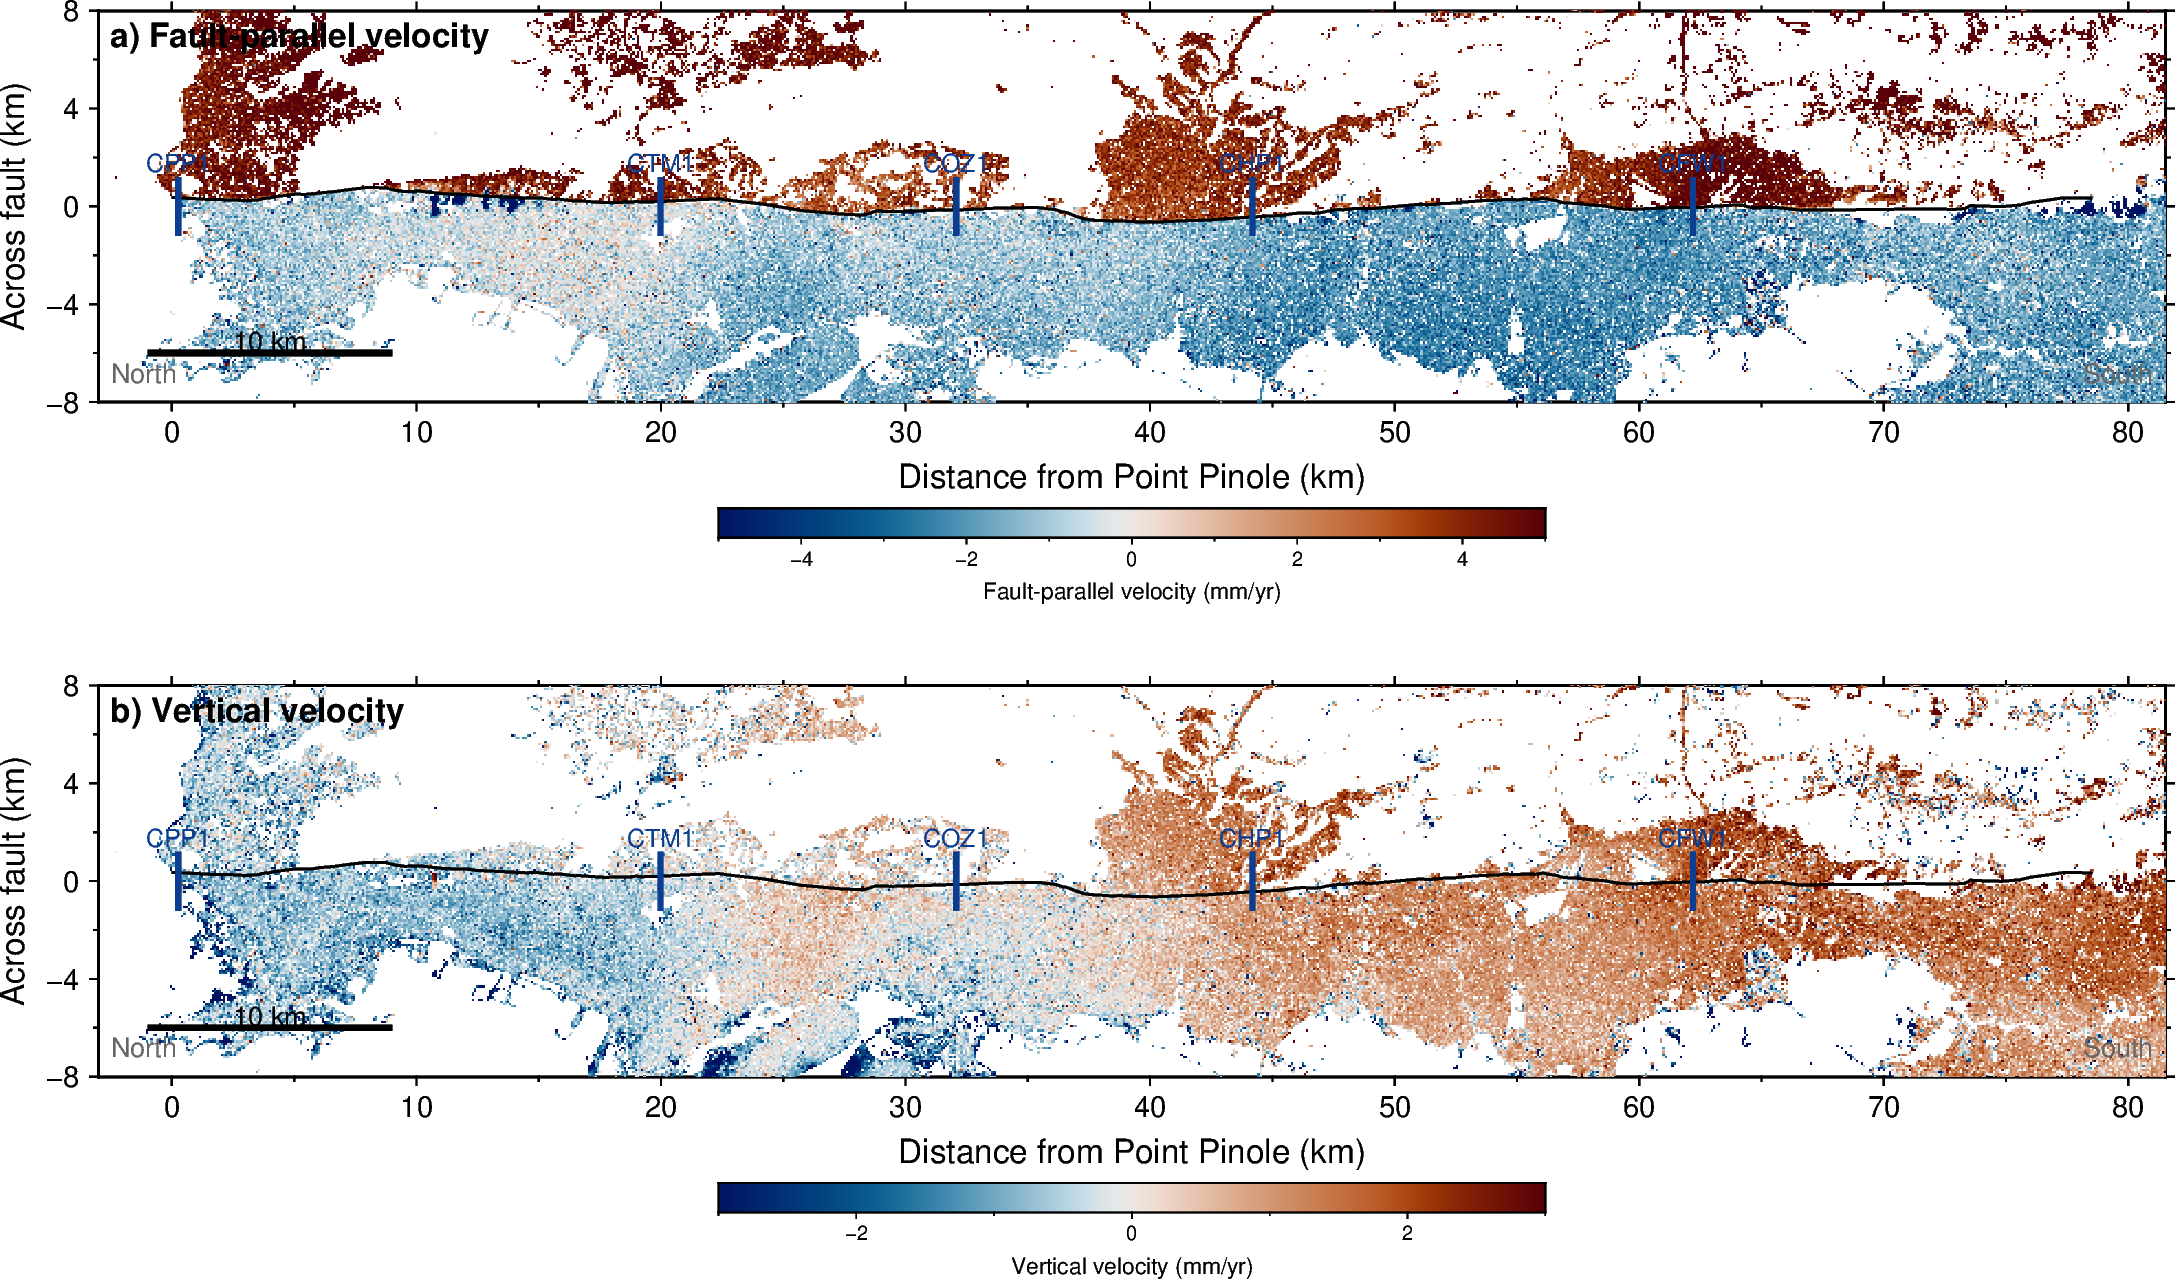

In [11]:
# --- the figure: two rotated map panels, journal double-column width ---
W, H = 17.5, 3.2                       # cm: panel width (double column) and height at true aspect
region = [-3.0, u_south + 3.0, -map_half_km, map_half_km]
H = W * (2 * map_half_km) / (region[1] - region[0])

fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p", FONT_LABEL="8p",
             MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p")

for i, (grid, series, title, label) in enumerate((
        (fp_rot, [-5, 5], "a) Fault-parallel velocity", "Fault-parallel velocity (mm/yr)"),
        (up_rot, [-3, 3], "b) Vertical velocity", "Vertical velocity (mm/yr)"))):
    if i:
        fig.shift_origin(yshift=f"-{H + 2.4}c")
    pygmt.makecpt(cmap="vik", series=series)
    fig.basemap(region=region, projection=f"X{W}c/{H}c",
                frame=["WSne", "xa10f5+lDistance from Point Pinole (km)", "ya4f2+lAcross fault (km)"])
    fig.grdimage(grid=grid, cmap=True, nan_transparent=True)
    fig.plot(x=tu, y=tv, pen="0.6p,black")                              # the mapped trace
    for code, u in u_cm.items():                                        # creepmeter ticks
        fig.plot(x=[u, u], y=[-1.2, 1.2], pen="1.4p,#0b3d91")
        fig.text(x=u, y=1.4, text=code, justify="BC", font="6p,Helvetica,#0b3d91")
    fig.text(x=region[0], y=region[3], text=title, justify="TL", offset="0.1c/-0.1c", font="8p,Helvetica-Bold")
    fig.text(x=region[0] + 0.5, y=-map_half_km + 0.8, text="North", justify="LB", font="6.5p,gray40")
    fig.text(x=region[1] - 0.5, y=-map_half_km + 0.8, text="South", justify="RB", font="6.5p,gray40")
    fig.plot(x=[region[0] + 2, region[0] + 12], y=[-map_half_km + 2.0] * 2, pen="1.5p,black")   # 10 km scale bar
    fig.text(x=region[0] + 7, y=-map_half_km + 2.1, text="10 km", justify="BC", font="6.5p")
    fig.colorbar(cmap=True, position=f"JBC+o0c/0.9c+w{W * 0.4}c/0.25c+h", frame=f"xa2f1+l{label}")

stem = os.path.join(fig_dir, f"fig02_velocity_maps_rotated_strike{strike:.1f}_clim5-3mm")
fig.savefig(stem + ".png", dpi=300, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
fig.savefig(stem + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved figure to:", stem + ".png")
fig.show()

## Figure: the five creepmeter transects

Grey points are every pixel in the 400 m swath, the line is the step fit.
The step at CFW1 (Fremont) is the number compared with the creepmeter in
notebook 04; here it is a sanity check that the decomposition produced
right-lateral creep of the right size everywhere along the fault.

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(7.2, 2.2), sharey=True)
for ax, (code, la, lo, name) in zip(axes, creepmeters):
    sub = xf[xf.code == code].sort_values("dist_m")
    step, pred = step_fit(sub.dist_m.values, sub.fp_vel.values)
    ax.scatter(sub.dist_m, sub.fp_vel, s=2, color="0.6", label="pixels")
    ax.plot(sub.dist_m, pred, color="#D55E00", lw=1.2, label="step fit")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"{code}: {step:.1f} mm/yr", fontsize=8)
    ax.set_xlabel("distance (m, + east)", fontsize=7)
    ax.tick_params(labelsize=7)
axes[0].set_ylabel("FP velocity (mm/yr)", fontsize=8)
axes[0].legend(fontsize=6, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"fig02_transects_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.png"), dpi=300)
plt.show()

/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_4562/171494569.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## REGISTER: every number this notebook contributes to the manuscript

The stats sidecar is the human-readable copy; the registry rows are what get
copied into Overleaf. `where` says which paragraph or figure the number feeds.

In [13]:
lines = [
    "02 VELOCITY DECOMPOSITION",
    f"inputs: GNSS-tied velocity mosaics, {attrs['LENGTH']} x {attrs['WIDTH']} px at {attrs['X_STEP']} m, EPSG {attrs['EPSG']}",
    f"mean fault strike used for the map: {strike:.2f} deg (clockwise from north)",
    f"pixels valid on both tracks: {both.sum()} ({100 * both.mean():.1f}%)",
    f"FP velocity median {np.nanmedian(fp):+.2f} mm/yr, 5-95% {np.nanpercentile(fp, 5):+.2f} to {np.nanpercentile(fp, 95):+.2f}",
    f"Up velocity median {np.nanmedian(up):+.2f} mm/yr, 5-95% {np.nanpercentile(up, 5):+.2f} to {np.nanpercentile(up, 95):+.2f}",
    f"hand re-derivation at {n_check} px: max |diff| FP {np.abs(diff_fp).max():.1e}, Up {np.abs(diff_up).max():.1e} mm/yr",
    "",
    "cross-fault FP velocity step at the creepmeters (east - west, mm/yr):",
] + [f"  {code}: {steps[code]:.2f}" for code in steps] + [
    "",
    f"MintPy {mintpy.__version__} (site-packages install in opera_disp_feb13)",
]
sidecar = REG.sidecar("02_velocity", lines)

REG.register("02_strike_mean_deg", strike, "deg", 2, where="M2", cell="strike", sidecar=sidecar)
REG.register("02_fp_valid_pct", 100 * np.isfinite(fp).mean(), "pct", 1, where="M2", cell="decompose", sidecar=sidecar)
REG.register("02_fp_median_mm_yr", np.nanmedian(fp), "mm/yr", 2, where="M2", cell="decompose", sidecar=sidecar)
for code in steps:
    REG.register(f"02_xfault_step_{code}_mm_yr", steps[code], "mm/yr", 2, where="M4, Fig S4", cell="transects", sidecar=sidecar)
REG.register("02_mintpy_version", mintpy.__version__, "1", 0, where="M1", cell="register", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition/02_velocity_stats.txt
  registered 02_strike_mean_deg = 144.10 deg  -> M2
  registered 02_fp_valid_pct = 33.3 pct  -> M2
  registered 02_fp_median_mm_yr = 1.31 mm/yr  -> M2
  registered 02_xfault_step_CPP1_mm_yr = 3.65 mm/yr  -> M4, Fig S4
  registered 02_xfault_step_CTM1_mm_yr = 3.77 mm/yr  -> M4, Fig S4


  registered 02_xfault_step_COZ1_mm_yr = 3.11 mm/yr  -> M4, Fig S4
  registered 02_xfault_step_CHP1_mm_yr = 4.94 mm/yr  -> M4, Fig S4
  registered 02_xfault_step_CFW1_mm_yr = 6.62 mm/yr  -> M4, Fig S4
  registered 02_mintpy_version = 1.6.2 1  -> M1
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'